In [1]:
# %% [1. UNIVERSAL IMPORTS]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from sklearn.datasets import load_iris, load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler

from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.svm import SVC, SVR
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB

from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay,
    r2_score, mean_squared_error, mean_absolute_error,
    silhouette_score, davies_bouldin_score
)

sns.set_theme(style='whitegrid')


In [2]:
# %% [2. DATA LOADING - UNSUPERVISED]
# --- Option A: Built-in Dataset ---
data = load_iris(as_frame=True)
df = data.frame
X = data.data

# --- Option B: CSV Load ---
# df = pd.read_csv('dataset.csv')
# df = df.dropna()
# df = pd.get_dummies(df, drop_first=True)
# X = df.copy()

print(f"Feature matrix shape: {X.shape}")


Feature matrix shape: (150, 4)


<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


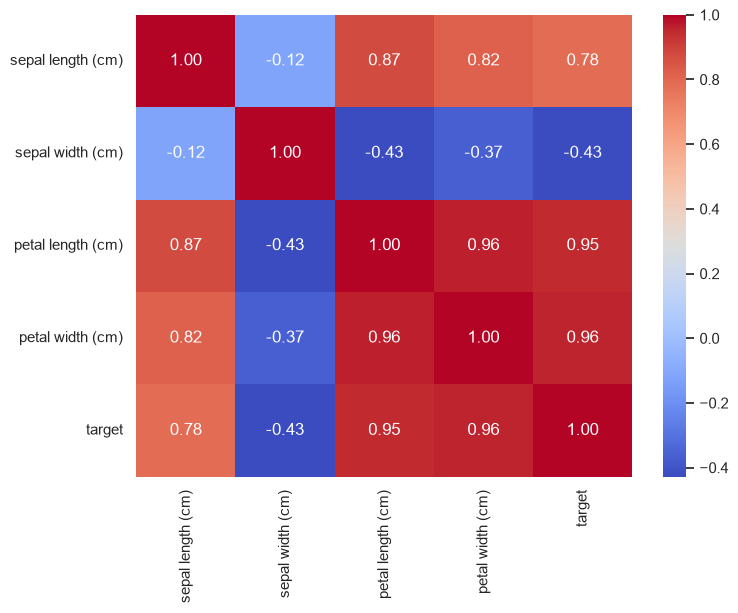

In [3]:
# %% [3. EXPLORATORY DATA ANALYSIS]
df.info()
print(df.isnull().sum())
display(df.describe())

plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.show()

# if 'target' in df.columns:
#     sns.pairplot(df, hue='target', palette='Dark2')
# else:
#     sns.pairplot(df, palette='Dark2')
# plt.show()


In [4]:
# %% [4. FEATURE SCALING]
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)


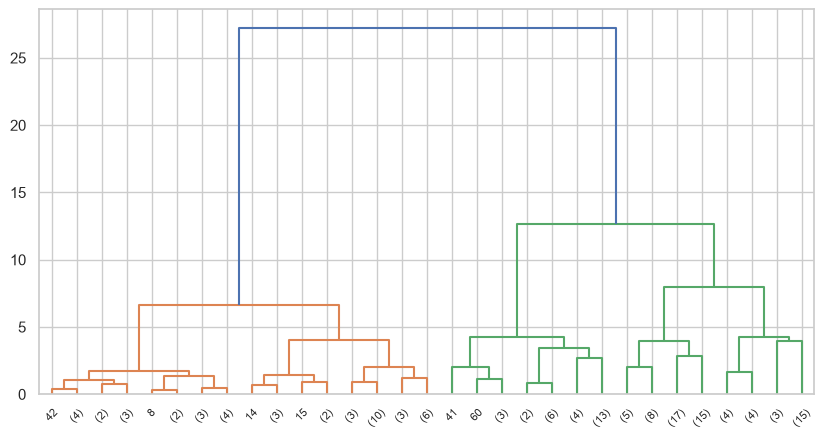

In [5]:
# %% [6. MODEL - HAC]
model = AgglomerativeClustering(n_clusters=3, linkage='ward')
clusters = model.fit_predict(X_scaled)
df['Cluster'] = clusters

plt.figure(figsize=(10, 5))
dendrogram(linkage(X_scaled, method='ward'), truncate_mode='level', p=4)
plt.show()


In [6]:
model# %% [7. EVALUATION - UNSUPERVISED]
mask = clusters != -1
if len(set(clusters[mask])) > 1:
    sil = silhouette_score(X_scaled[mask], clusters[mask])
    dbi = davies_bouldin_score(X_scaled[mask], clusters[mask])
    print(f"Silhouette Score     : {sil:.4f}")
    print(f"Davies-Bouldin Index : {dbi:.4f}")
else:
    print("Fewer than 2 clusters formed.")


Silhouette Score     : 0.4467
Davies-Bouldin Index : 0.8035


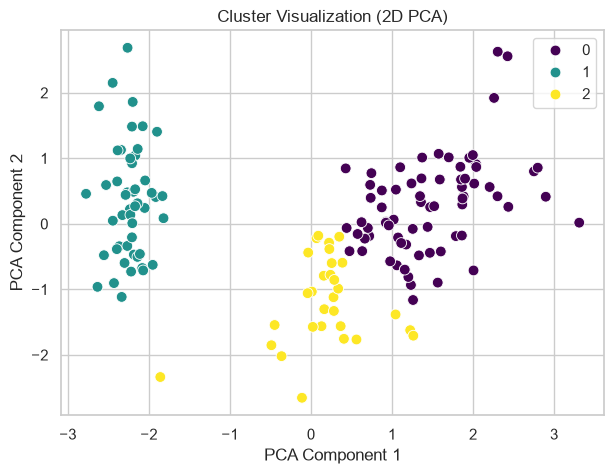

In [7]:
# %% [8. VISUALIZATION - UNSUPERVISED CLUSTERS]
pca_vis = PCA(n_components=2)
X_vis = pca_vis.fit_transform(X_scaled)

plt.figure(figsize=(7, 5))
sns.scatterplot(x=X_vis[:, 0], y=X_vis[:, 1], hue=clusters, palette='viridis', s=60)
if hasattr(model, 'cluster_centers_'):
    centers_vis = pca_vis.transform(model.cluster_centers_)
    plt.scatter(centers_vis[:, 0], centers_vis[:, 1], c='red', s=200, marker='X', label='Centroids')
    plt.legend()
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.title('Cluster Visualization (2D PCA)')
plt.show()
